# 01 — EDA: BBBC041v1

Ноутбук лише читає збережені артефакти (`reports/tables/`, `data/processed/coco/`, `data/splits/`) і викликає функції з `malaria_ssl`. Згенерувати артефакти:

```
python scripts/prepare_data.py
python scripts/compute_stats.py
```

In [1]:
import json

import pandas as pd

from malaria_ssl.data.stats import boxes_frame, images_frame, load_coco
from malaria_ssl.data import viz
from malaria_ssl.utils.config import load_config, resolve_path

cfg = load_config(resolve_path('configs/data.yaml'))
TABLES = resolve_path('reports/tables')
COCO_DIR = resolve_path(cfg['paths']['coco_dir'])
IMAGES_DIR = resolve_path(cfg['paths']['raw_root']) / 'images'
SPLITS = ['train', 'val', 'test']
pd.set_option('display.float_format', '{:.3f}'.format)

## Збережені статистики

In [2]:
stats = json.loads((TABLES / 'dataset_stats.json').read_text(encoding='utf-8'))
pd.DataFrame(stats['splits']).T

,images,boxes
train,1027,67719
val,181,12394
test,120,5922


In [3]:
class_counts = pd.read_csv(TABLES / 'class_counts.csv', index_col='class')
class_counts

,test_boxes,train_boxes,val_boxes,test_images,train_images,val_images,total_boxes,share_of_boxes,imbalance_vs_majority
class,,,,,,,,,
red blood cell,5614,65401,12019,120,1027,181,83034,0.965,1.000
leukocyte,0,89,14,0,80,14,103,0.001,806.155
gametocyte,12,124,20,11,116,20,156,0.002,532.269
ring,169,304,49,57,207,37,522,0.006,159.069
trophozoite,111,1269,204,59,507,89,1584,0.018,52.420
schizont,11,154,25,9,133,24,190,0.002,437.021
difficult,5,378,63,5,291,51,446,0.005,186.175


In [4]:
pd.read_csv(TABLES / 'boxes_per_image.csv', index_col='split')

,count,mean,median,std,min,max,n_images_over_100
split,,,,,,,
test,120.000,49.350,49.000,17.767,12.000,108.000,2.000
train,1027.000,65.939,60.000,33.535,9.000,216.000,113.000
val,181.000,68.475,58.000,40.010,16.000,223.000,24.000
all,1328.000,64.785,58.000,33.754,9.000,223.000,139.000


In [5]:
print('image with most boxes:', stats['max_boxes_image'])
pd.read_csv(TABLES / 'image_sizes.csv', index_col='size')

image with most boxes: {'split': 'val', 'file_name': '252071ac-e9f2-41d2-abbb-87ef01b8a997.png', 'n_boxes': 223}


,test,train,val,total
size,,,,
1600x1200,0,1027,181,1208
1944x1383,120,0,0,120


In [6]:
box_sizes = pd.read_csv(TABLES / 'box_sizes.csv')
box_sizes[(box_sizes['measure'] == 'side_max') & (box_sizes['class'] == 'ALL')]

,split,class,measure,n,mean,q00,q01,q05,q25,q50,q75,q95,q99,q100
38,train,ALL,side_max,67719,114.474,66.000,84.000,92.000,104.000,113.000,123.000,140.000,163.000,255.000
78,val,ALL,side_max,12394,113.987,69.000,84.000,91.000,103.000,113.000,123.000,139.000,162.000,231.000
113,test,ALL,side_max,5922,145.191,82.000,99.000,117.000,134.000,144.000,154.000,178.000,204.000,309.000
153,ALL,ALL,side_max,86035,116.518,66.000,84.000,92.000,105.000,115.000,126.000,148.000,172.000,309.000


In [7]:
box_sizes[(box_sizes['measure'] == 'side_max') & (box_sizes['split'] == 'ALL')]

,split,class,measure,n,mean,q00,q01,q05,q25,q50,q75,q95,q99,q100
118,ALL,red blood cell,side_max,83034,115.453,66.000,84.000,92.000,104.000,114.000,125.000,145.000,165.000,309.000
123,ALL,leukocyte,side_max,103,133.602,69.000,82.040,93.300,108.000,127.000,151.500,194.600,231.820,250.000
128,ALL,gametocyte,side_max,156,144.769,95.000,97.200,119.750,131.000,142.000,157.000,181.000,198.050,209.000
133,ALL,ring,side_max,522,139.806,88.000,98.420,112.000,125.250,135.000,152.000,180.900,205.580,240.000
138,ALL,trophozoite,side_max,1584,147.552,80.000,98.830,116.000,132.000,143.000,160.000,193.000,220.340,296.000
143,ALL,schizont,side_max,190,155.432,84.000,92.670,118.900,142.000,154.000,170.750,191.100,206.550,217.000
148,ALL,difficult,side_max,446,146.937,87.000,99.800,120.250,132.000,144.000,160.000,182.000,209.300,252.000
153,ALL,ALL,side_max,86035,116.518,66.000,84.000,92.000,105.000,115.000,126.000,148.000,172.000,309.000


## Конвертація та спліти

In [8]:
convert_summary = json.loads((COCO_DIR.parent / 'convert_summary.json').read_text(encoding='utf-8'))
{k: convert_summary[k] for k in ['n_image_files', 'n_train_records', 'n_test_records', 'n_unlabeled', 'orientation', 'binary_dropped']}

{'n_image_files': 1328,
 'n_train_records': 1208,
 'n_test_records': 120,
 'n_unlabeled': 0,
 'orientation': {'train': {'boxes': 80113,
   'violations_r_is_row': 0,
   'violations_r_is_col': 21549},
  'test': {'boxes': 5922,
   'violations_r_is_row': 0,
   'violations_r_is_col': 1631}},
 'binary_dropped': {'train_full': {'difficult': 441},
  'test': {'difficult': 5}}}

In [9]:
split_meta = json.loads((resolve_path(cfg['paths']['splits_dir']) / 'split_meta.json').read_text(encoding='utf-8'))
print(split_meta['n_images'], 'val fraction =', round(split_meta['val_fraction_actual'], 3))
print('near-duplicate pairs:', split_meta['near_duplicate_pairs'])
pd.DataFrame({s: {c: v['images'] for c, v in d.items()} for s, d in split_meta['class_counts'].items()})

{'train': 1027, 'val': 181, 'test': 120} val fraction = 0.15
near-duplicate pairs: [{'a': '3061aac0-cda3-47d1-8c48-6293e9ffdf36.png', 'b': 'f329e01b-fbd3-4fb5-9738-a7ff4c8622b8.png', 'hamming': 8, 'splits': ['train', 'train']}]


,train,val,test
red blood cell,1027,181,120
leukocyte,80,14,0
gametocyte,116,20,11
ring,207,37,57
trophozoite,507,89,59
schizont,133,24,9
difficult,291,51,5


## Графіки

In [10]:
cocos = {s: load_coco(COCO_DIR / f'{s}.json') for s in SPLITS}
images = pd.concat([images_frame(cocos[s], s) for s in SPLITS], ignore_index=True)
boxes = pd.concat([boxes_frame(cocos[s], s) for s in SPLITS], ignore_index=True)

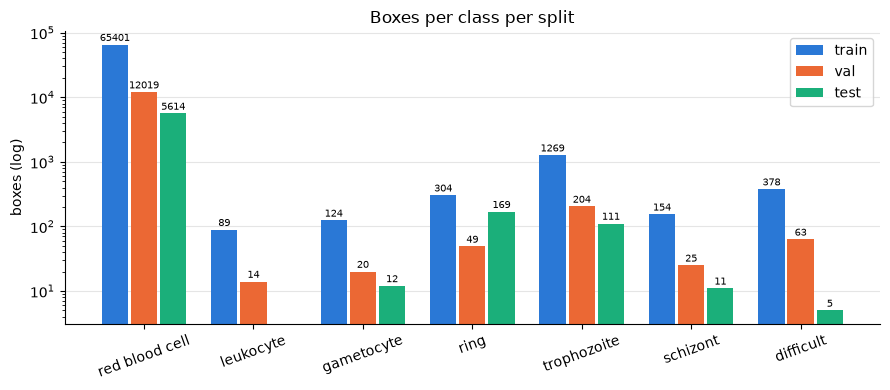

In [11]:
viz.plot_class_distribution(class_counts, SPLITS);

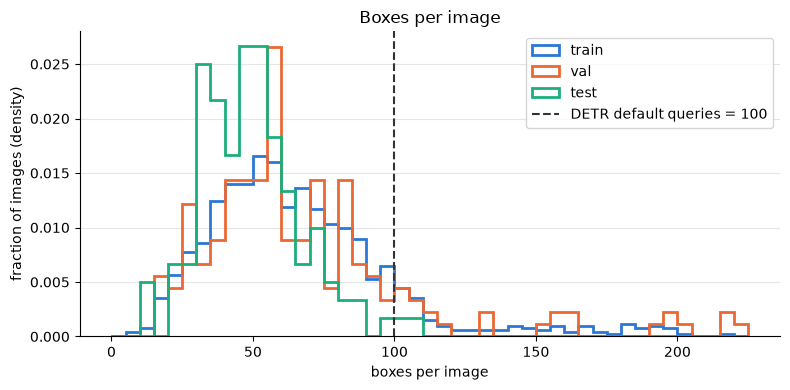

In [12]:
viz.plot_boxes_per_image(images, queries=stats['detr_default_queries']);

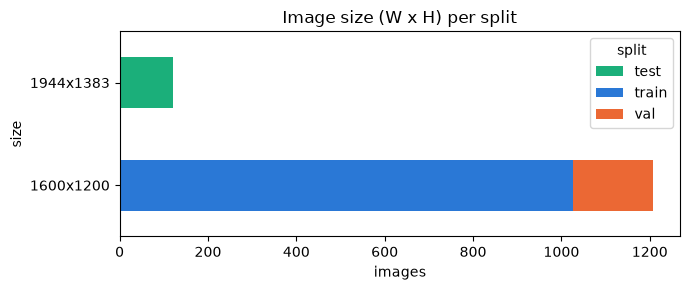

In [13]:
viz.plot_image_sizes(images);

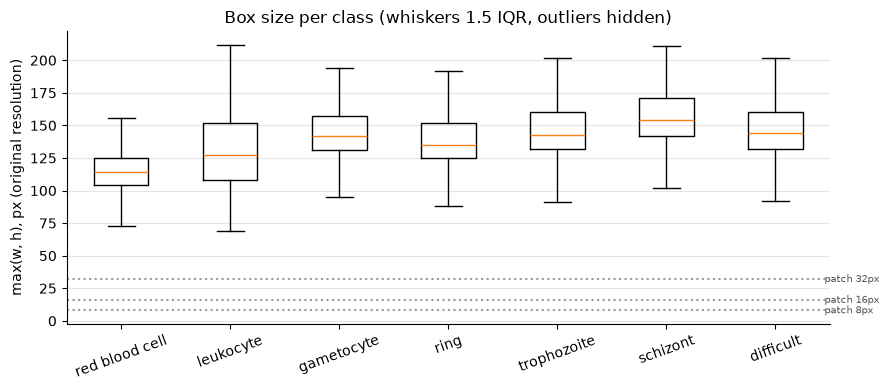

In [14]:
viz.plot_box_sizes(boxes, by='class');

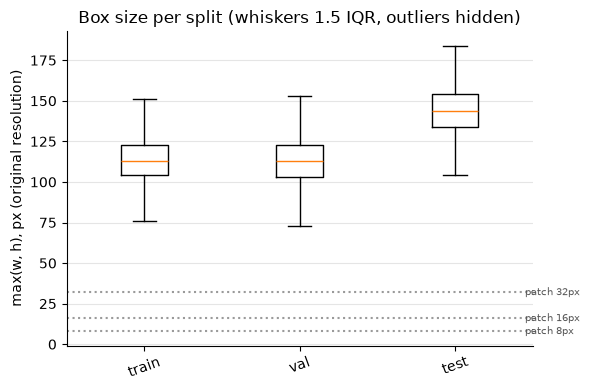

In [15]:
viz.plot_box_sizes(boxes, by='split');

## Приклади кожного класу (кропи з train)

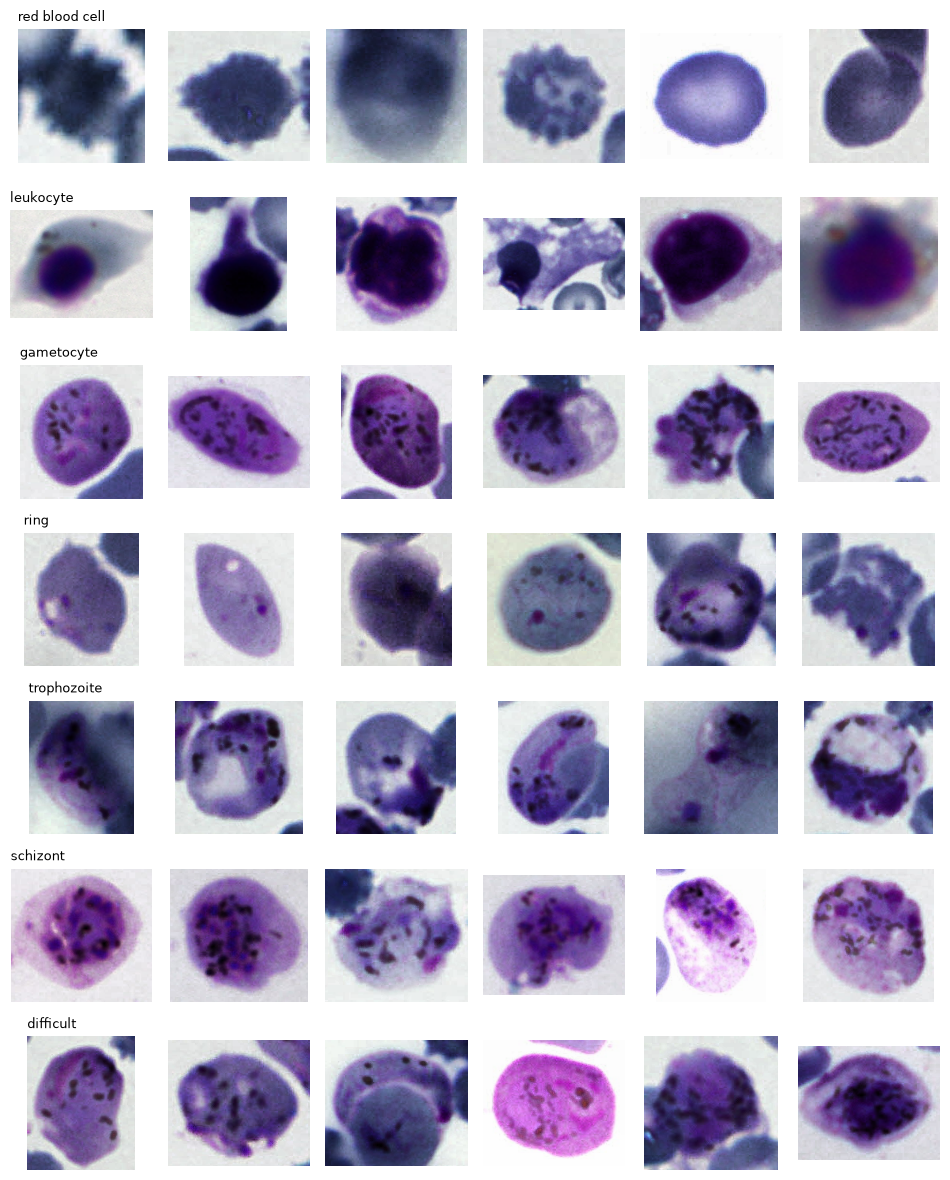

In [16]:
viz.plot_class_crops(cocos['train'], IMAGES_DIR, per_class=6, seed=cfg['seed']);